In [1]:
from torchvision import datasets, transforms
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.manifold import TSNE
import seaborn as sns
import random
import numpy as np
from NetworkArchitecture import Neural_FashionMNIST

In [2]:
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=512,
    shuffle=True
)

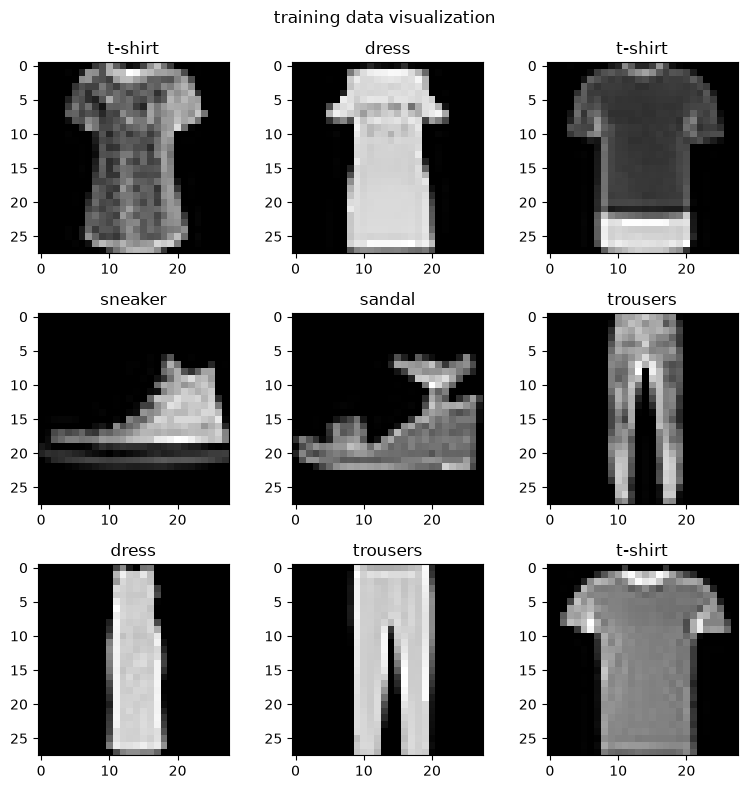

In [3]:
labels_map = {
    0: 't-shirt',
    1: 'trousers',
    2: 'pullover',
    3: 'dress',
    4: 'coat',
    5: 'sandal',
    6: 'shirt',
    7: 'sneaker',
    8: 'bag',
    9: 'ankle boot'
}
fig = plt.figure(figsize=(8,8))
fig.suptitle("training data visualization")
cols, rows = 3, 3
for i in range(len(labels_map) - 1):
    sample_idx = torch.randint(low=0, high=len(test_data), size=(1,)).item()
    sample_img, label = test_data[sample_idx]
    fig.add_subplot(rows, cols, i+1)
    plt.tight_layout()
    plt.title(labels_map[label])
    plt.imshow(sample_img.squeeze(), cmap="gray")
plt.tight_layout()
plt.show()

In [4]:
models = ['model-trained.pt','model-trained2.pt']

loaded_models = []
for path in models:
    m = Neural_FashionMNIST()
    m.load_state_dict(torch.load(path, weights_only=True))
    m.eval()
    loaded_models.append(m)

              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1000
           1       0.99      0.98      0.99      1000
           2       0.90      0.88      0.89      1000
           3       0.92      0.93      0.92      1000
           4       0.89      0.89      0.89      1000
           5       0.98      0.96      0.97      1000
           6       0.76      0.77      0.76      1000
           7       0.93      0.98      0.95      1000
           8       0.98      0.98      0.98      1000
           9       0.97      0.96      0.96      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000

              precision    recall  f1-score   support

           0       0.86      0.89      0.88      1000
           1       0.99      0.98      0.99      1000
           2       0.86      0.88      0.87      1000
           3       0.90 

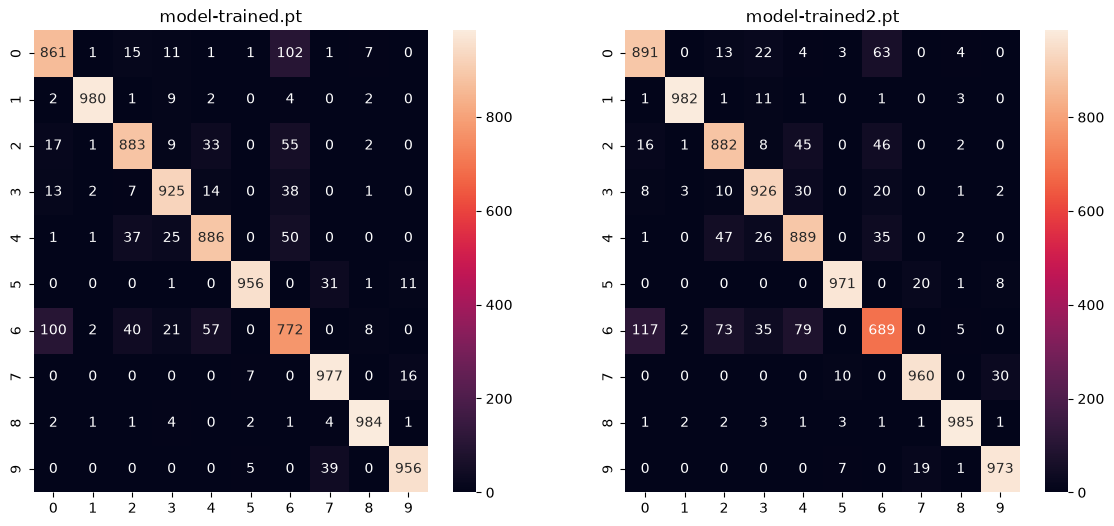

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for i, model in enumerate(loaded_models):
    y_true = test_data.targets
    y_pred = []

    with torch.no_grad():
        for X, y in test_data:
            X = X.view(-1, 1, 28, 28)
            pred_class = int(torch.argmax(model(X)[0]))
            y_pred.append(pred_class)

    print(classification_report(y_true, y_pred))
    cm = confusion_matrix(y_true, y_pred)
    axes[i].set_title(models[i])
    sns.heatmap(cm, annot=True, fmt='.0f', ax=axes[i])
plt.show()

/var/folders/qg/scd7gbws4sx_c7pwhp5cw8jw0000gn/T/ipykernel_10635/1237595839.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  tensor_in = torch.tensor(img).view(-1, 1, 28, 28)


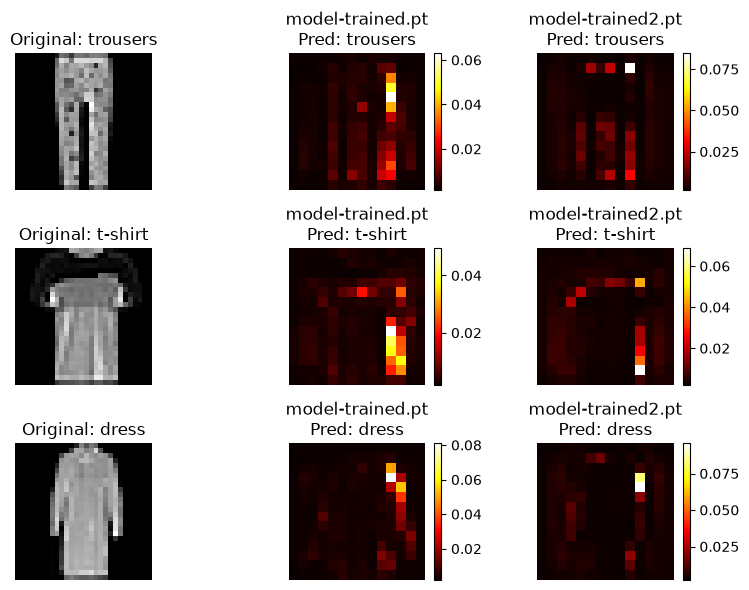

In [24]:
num_samples = 3

sample_imgs, sample_labels = [], []
for i in range(num_samples):
    sample_img, label = test_data[random.randint(0, len(test_data))]

    sample_imgs.append(sample_img)
    sample_labels.append(label)

fig, axes = plt.subplots(num_samples, 3, figsize=(8, 6))

for i in range(num_samples):
    img = sample_imgs[i]
    label = sample_labels[i]
    tensor_in = torch.tensor(img).view(-1, 1, 28, 28)

    ax_img = axes[i, 0]
    ax_img.imshow(img.squeeze(), cmap='grey')
    ax_img.set_title(f'Original: {labels_map[label]}')
    ax_img.axis('off')

    for j, model in enumerate(loaded_models):
        with torch.no_grad():
            output, weights, _ = model(tensor_in)
            
        pred_class = int(torch.argmax(output, dim=1))
        
        attn_size = int(np.sqrt(weights.shape[-1])) 
        weights_tensor = weights.squeeze().mean(dim=0).detach().cpu().numpy().reshape(attn_size, attn_size)
        
        ax_attn = axes[i, j + 1]
        im = ax_attn.imshow(weights_tensor, cmap="hot")
        ax_attn.set_title(f"{models[j]}\nPred: {labels_map[pred_class]}")
        ax_attn.axis('off')
        fig.colorbar(im, ax=ax_attn, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


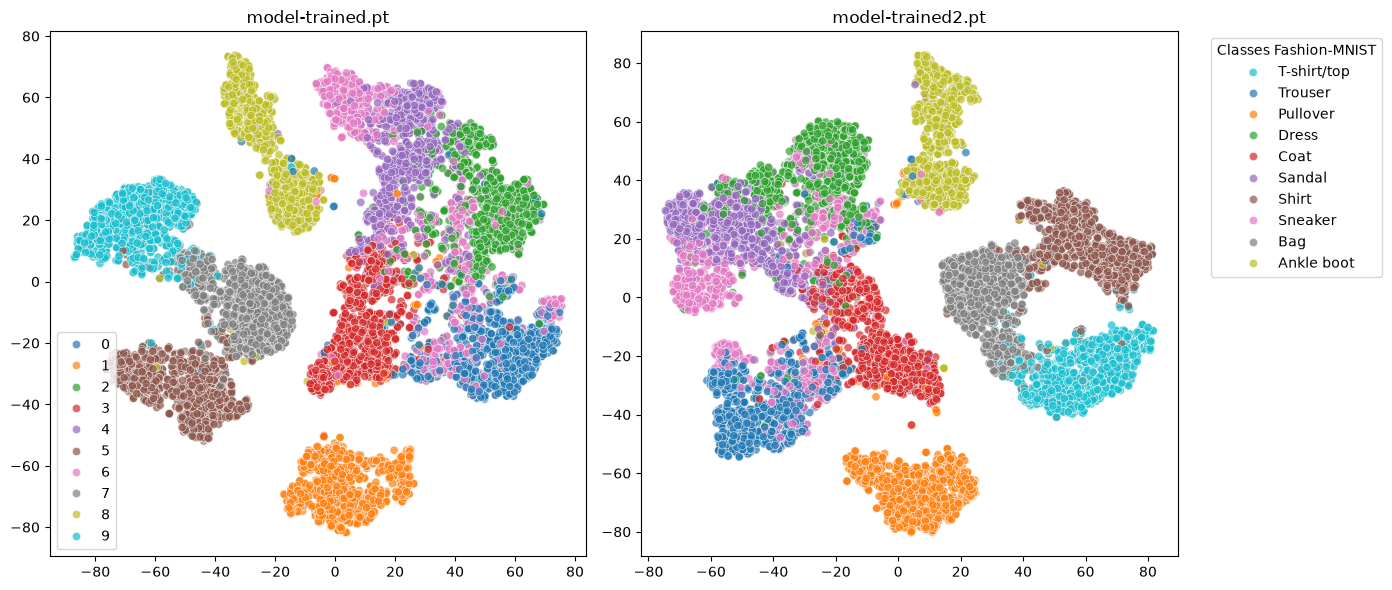

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

i = 0

all_labels = []
all_images = []

for images, labels in test_loader:
    all_images.append(images)
    all_labels.append(labels.numpy())

    if test_loader.batch_size > 3000:
        break

all_images = torch.cat(all_images, dim=0).to(device)
all_labels = np.concatenate(all_labels, axis=0)

if len(loaded_models) == 1:
    axes = [axes]

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

for i, model in enumerate(loaded_models):
    model.to(device)
    model.eval()

    all_features = []

    with torch.no_grad():
        outputs, _, features = model(all_images)
        all_features = features.cpu().numpy()

    tsne = TSNE(n_components=2, random_state=42)
    features_2d = tsne.fit_transform(all_features)

    ax_features = axes[i]
    ax_features.set_title(models[i])

    sns.scatterplot(
        x=features_2d[:, 0], 
        y=features_2d[:, 1],
        hue=all_labels,
        palette="tab10",
        legend="full",
        alpha=0.7,
        ax=ax_features
    )

    classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
            'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.legend(title="Classes Fashion-MNIST", labels=classes, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()